# Notes about the Data
* For each object, trajectories numbered #0-#49 are collected at 150 load.
* All trajectories numbered #50-#99 are collected at 150 load. These trajectories are to be categorized as to have been collected with a broken pulley mechanism, thus having downgraded data quality.
    * These trajectories ONLY EXIST for four objects: Hard_Orange_Cylinder_Small, Hard_Red_Cylinder, Hard_Violet_Cylinder, and Hard_Yellow_Cylinder_Small
* All trajectories numbered #100-#149 are collected at 150 load. Only 17/21 objects have trajectories numbered #100-149. After this, a broken bending sensor was reported.
    * These trajectories DO NOT EXIST for the following objects: Hard_Spam, Soft_Yellow_Sponge
    * Soft_Blue_Die_Big has only two trajectories for these numbers.
* Trajectories numbered #200-224 are collected with the replacement sensor. The load is set to 120.
* Trajectories numbered #300-324 are collected with load 120.
* Trajectories numbered #400-424 are collected with load 45.
* Trajectory number #500 is with grasping and lifting (gravity effects the signal).
* Trajectories numbered #600-#780 are 'first grasps' for different objects. A first grasp is different from a regular grasp because the object's starting position is slightly outside the concave palm and thus the object moves. It represents a transient situation rather than a stable grasp feedback sequence.
* Trajectories numbered #800-#850 are also first grasp trajectories. These were done for only three objects: Hard_Red_Cylinder, Soft_Blue_Cube, and Soft_Rosa_Cylinder
* Trajectories numbered #1000-#1051 are double grasp trajectories. Each consists of two grasps, a transient "first grasp" and then a stable "second grasp". For analysis we split each recording into two time series signals with the same ID number but different descriptions.
* Trajectories numbered #1100-#1491 are double grasp trajectories. Each consists of two grasps, a transient "first grasp" and then a stable "second grasp". For analysis we split each recording into two time series signals with the same ID number but different descriptions.

# Libraries

In [1]:
#General Purpose
import copy
import os
from tqdm import tqdm

#GUI
import ipywidgets as widgets
from ipywidgets import interact

#Maths and Plotting
import numpy as np
import scipy
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1 import make_axes_locatable
import plotly.express as px

#Stochastic Methods
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder

#Machine Learning
import torch
import torch.nn as nn
import torch.optim as optim
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import Dataset, TensorDataset, DataLoader

# Dataset Dictionaries

In [2]:
name_to_ID = {
    'Hard_Yellow_Cylinder_Small':0,
    'Hard_Orange_Cylinder_Small':1,
    'Hard_Red_Cylinder':2,
    'Hard_Violet_Cylinder':3,
    'Hard_Green_Cylinder':4,
    'Hard_Yellow_Cylinder_Big':5,
    'Hard_Orange_Cylinder_Big':6,
    'Hard_Blue_Cylinder':7,
    'Hard_Rubiks_Cube':8,
    'Hard_Spam':9,
    'Soft_Blue_Cube':10,
    'Soft_Blue_Die_Small':11,
    'Soft_Blue_Die_Big':12,
    'Soft_Brown_Cuboid':13,
    'Soft_Kinova_Cube':14,
    'Soft_Rosa_Cylinder':15,
    'Soft_Rosa_Die':16,
    'Soft_White_Die':17,
    'Soft_Yellow_Cube':18,
    'Soft_Yellow_Sponge':19,
    'Without_Object':20
}

name_to_color = {
    'Hard_Yellow_Cylinder_Small':'yellow',
    'Hard_Orange_Cylinder_Small':'orange',
    'Hard_Red_Cylinder':'red',
    'Hard_Violet_Cylinder':'purple',
    'Hard_Green_Cylinder':'green',
    'Hard_Yellow_Cylinder_Big':'darkgoldenrod',
    'Hard_Orange_Cylinder_Big':'sienna',
    'Hard_Blue_Cylinder':'blue',
    'Hard_Rubiks_Cube':'lightgreen',
    'Hard_Spam':'navy',
    'Soft_Blue_Cube':'cyan',
    'Soft_Blue_Die_Small':'gray',
    'Soft_Blue_Die_Big':'aquamarine',
    'Soft_Brown_Cuboid':'maroon',
    'Soft_Kinova_Cube':'tan',
    'Soft_Rosa_Cylinder':'deeppink',
    'Soft_Rosa_Die':'palevioletred',
    'Soft_White_Die':'lightsteelblue',
    'Soft_Yellow_Cube':'olive',
    'Soft_Yellow_Sponge':'gold',
    'Without_Object':'black'
}

load_to_exp = {
    "45" : 400,
    "120": 200,
    "150": 0
}

load_to_marker_matplotlib = {
    "45" : 'o',
    "120": 'x',
    "150": '^'
}

load_to_marker_plotly = {
    "45" : 'circle',
    "120": 'square',
    "150": 'diamond'
} # Available 2D Markers: circle, square, diamond, cross, x, triangle-up, triangle-down, triangle-left, triangle-right, pentagon, hexagon, star, hourglass, bowtie
# Available 3D Markers: circle, square, diamond, cross, x, circle-open, square-open, diamond-open, cross-open, x-open

signals_list = ["Time","Fingert._ID2","Bottom_ID2","Fingert._ID4","Middle_ID4","Bottom_ID4",
                "Fingert._ID2_comp","Bottom_ID2_comp","Fingert. ID4 comp","Middle ID4 comp","Bottom ID4 comp",
                "Motor ID2 Current","Motor ID4 Current"]

# Functions

## Analysis

In [3]:
def extract_features(array: np.array) -> np.array:
    # features computed default: Min, Max, Mean, Kurtosis, Skewness, Median, Std, Var, Diff1_mean, Diff2_mean, Diff1_max, Diff2_max, Trapz, Hilbert
    
    features = []

    max_val = np.max(array)
    features.append(max_val)

    min_val = np.min(array[:np.argmax(array)])
    features.append(min_val)

    rise_time = np.abs(np.argmax(array)-np.argmin(array[:np.argmax(array)]))
    features.append(rise_time)

    mean = np.mean(array)
    features.append(mean)

    kurtosis = scipy.stats.kurtosis(array, fisher=False)
    features.append(kurtosis)

    skewness = scipy.stats.skew(array)
    features.append(skewness)

    median = np.median(array)
    features.append(median)

    std = np.std(array)
    features.append(std)

    var = np.var(array)
    features.append(var)

    diff_1_mean = np.mean(np.diff(array))
    features.append(diff_1_mean)

    diff_2_mean = np.mean(np.diff(array, n=2))
    features.append(diff_2_mean)

    diff_1_max = np.max(np.diff(array))
    features.append(diff_1_max)

    diff_2_max = np.max(np.diff(array, n=2))
    features.append(diff_2_max)

    sum_val = np.sum(array)
    features.append(sum_val)

    zero_mean_array = array - mean
    hilbert_transform = scipy.signal.hilbert(zero_mean_array)
    amp_hilbert = np.sqrt(np.real(hilbert_transform) ** 2 + np.imag(hilbert_transform) ** 2)
    amp_mean_hilbert = np.mean(amp_hilbert)
    features.append(amp_mean_hilbert)

    return np.array(features)

# Loading all the data

In [4]:
all_data_df = pd.read_pickle("./all_data_df.pkl")
print("Number of Recordings: {}".format(all_data_df.shape[0]))
print("Columns: {}".format(all_data_df.columns))

Number of Recordings: 4486
Columns: Index(['Object_Name', 'Exp_Num', 'Load', 'Series', 'Time', 'Fingert._ID2',
       'Bottom_ID2', 'Fingert._ID4', 'Middle_ID4', 'Bottom_ID4',
       'Fingert._ID2_comp', 'Bottom_ID2_comp', 'Fingert. ID4 comp',
       'Middle ID4 comp', 'Bottom ID4 comp', 'Motor ID2 Current',
       'Motor ID4 Current', 'Object_ID', 'Color'],
      dtype='object')


# GUI to visualize Raw Data

In [5]:
mode_dropdown = widgets.Dropdown(
    options = [("None",0),
               ("Different signals, Same object, Same load", 1), 
               ("Same signal, Different objects, Same load", 2),
               ("Same signal, Same object, Different loads", 3)
              ],
    value=0,
    description = ""
)
mode_column = widgets.VBox([
    widgets.HTML("<center><b>Plotting Mode</b></center>"),
    mode_dropdown
])

load_checkboxes = [widgets.Checkbox(value=False, description=load) for load in sorted(all_data_df['Load'].unique())]
load_column = widgets.VBox([
    widgets.HTML("<center><b>List of Loads</b></center>"),
    *load_checkboxes
])

object_checkboxes = [widgets.Checkbox(value=False, description=object_name) for object_name in sorted(all_data_df['Object_Name'].unique())]
object_column = widgets.VBox([
    widgets.HTML("<center><b>List of Objects</b></center>"),
    *object_checkboxes
])
signal_checkboxes = [widgets.Checkbox(value=False, description=signal_name) for signal_name in signals_list]
signal_column = widgets.VBox([
    widgets.HTML("<center><b>List of Signals</b></center>"),
    *signal_checkboxes
])

row = widgets.HBox([mode_column, load_column, object_column, signal_column])
display(row)

In [6]:
plot_mode = mode_dropdown.value
selected_loads_list = [checkbox.description for checkbox in load_checkboxes if checkbox.value==True]
selected_objects_list = [checkbox.description for checkbox in object_checkboxes if checkbox.value==True]
selected_signals_list = [checkbox.description for checkbox in signal_checkboxes if checkbox.value==True]

if plot_mode == 0:
    print("Plotting off")
elif plot_mode == 1:
    for object_name in selected_objects_list:
        for load in selected_loads_list:
            plt.figure()
            row = all_data_df.loc[(all_data_df['Object_Name'] == object_name) & (all_data_df['Exp_Num'] == load_to_exp[load])]
            for signal_name in selected_signals_list:
                plt.plot(row["Time"].iloc[0], row[signal_name].iloc[0], label = signal_name)
            plt.xlabel("Time", fontsize = 'x-large')
            plt.ylabel("Feedback", fontsize = 'x-large')
            plt.grid()
            plt.title("{}_{}".format(object_name, load), fontsize = 'x-large')
            plt.legend(loc='center left', fontsize = "large", bbox_to_anchor = (1, 0.5))
            #plt.savefig('/home/shubhan_patni/Downloads/Raw_Current.png', dpi= 300, bbox_inches="tight")
elif plot_mode == 2:
    for signal_name in selected_signals_list:
        for load in selected_loads_list:
            plt.figure()
            for object_name in selected_objects_list:
                row = all_data_df.loc[(all_data_df['Object_Name'] == object_name) & (all_data_df['Exp_Num'] == load_to_exp[load])]
                plt.plot(row["Time"].iloc[0], row[signal_name].iloc[0], color = row['Color'].iloc[0], label = object_name)
            plt.xlabel("Time")
            plt.ylabel("Feedback")
            plt.grid()
            plt.title("{}_{}".format(signal_name, load))
            plt.legend(loc='center left', bbox_to_anchor = (1, 0.5))
elif plot_mode == 3:
    for object_name in selected_objects_list:
        for signal_name in selected_signals_list:
            plt.figure()
            for load in selected_loads_list:
                row = all_data_df.loc[(all_data_df['Object_Name'] == object_name) & (all_data_df['Exp_Num'] == load_to_exp[load])]
                plt.plot(row["Time"].iloc[0], row[signal_name].iloc[0], color = row['Color'].iloc[0], marker = load_to_marker_matplotlib[load], label = str(load))
            plt.xlabel("Time")
            plt.ylabel("Feedback")
            plt.grid()
            plt.title("{}_{}".format(object_name, signal_name))
            plt.legend(loc='center left', bbox_to_anchor = (1, 0.5))

Plotting off


# Feature Extraction

In [7]:
all_features_df = all_data_df[['Object_Name','Load','Exp_Num','Series','Object_ID','Color']].copy()
for signal_name in tqdm(signals_list):
    if signal_name != "Time":
        all_features_df[signal_name] = all_data_df[signal_name].map(extract_features)

100%|███████████████████████████████████████████| 13/13 [01:29<00:00,  6.89s/it]


In [8]:
analyse_signal_checkboxes = [widgets.Checkbox(value=False, description=signal_name) for signal_name in signals_list]
analyse_signal_column = widgets.VBox([
    widgets.HTML("<center><b>List of Signals</b></center>"),
    *analyse_signal_checkboxes
])

row = widgets.HBox([analyse_signal_column])
display(row)

In [9]:
analyse_signals_list = [checkbox.description for checkbox in analyse_signal_checkboxes if checkbox.value==True]

X = np.hstack([
    np.vstack(all_features_df[signal_name].to_numpy())
    for signal_name in analyse_signals_list
])

# ---------------------------------------------------------------------------
# NOTE ON SCALING
# The scaling below is used ONLY for the unsupervised PCA visualisation.
# PCA here is exploratory (no labels, no train/test split involved), so a
# dataset-wide fit is appropriate and the plots are unchanged.
#
# The supervised classifiers DO NOT use these values. 'Features' now stores the
# RAW (unscaled) feature vectors; standardisation for the classifiers is fitted
# on the training split only, in the "Classifiers" section further down.
# ---------------------------------------------------------------------------

# Scaling (visualisation only)
scaler_viz = StandardScaler()
X_scaled_viz = scaler_viz.fit_transform(X)

# Raw features are what the supervised pipeline consumes
all_features_df['Features'] = list(X)

# Principal Component Analysis (visualisation only)
pca = PCA(n_components=3)
X_pca_scaled = pca.fit_transform(X_scaled_viz)
print("Explained Variation: {:.3f}".format(np.sum(pca.explained_variance_ratio_)))
all_features_df["PCA1"] = X_pca_scaled[:,0]
all_features_df["PCA2"] = X_pca_scaled[:,1]
all_features_df["PCA3"] = X_pca_scaled[:,2]

Explained Variation: 0.529


In [10]:
analyse_series_checkboxes = [widgets.Checkbox(value=False, description=load) for load in sorted(all_data_df['Series'].unique())]
analyse_series_column = widgets.VBox([
    widgets.HTML("<center><b>List of Data</b></center>"),
    *analyse_series_checkboxes
])

analyse_object_checkboxes = [widgets.Checkbox(value=False, description=object_name) for object_name in sorted(all_data_df['Object_Name'].unique())]
analyse_object_column = widgets.VBox([
    widgets.HTML("<center><b>List of Objects</b></center>"),
    *analyse_object_checkboxes
])

row = widgets.HBox([analyse_series_column, analyse_object_column])
display(row)

In [11]:
analyse_series_list = [checkbox.description for checkbox in analyse_series_checkboxes if checkbox.value==True]
analyse_objects_list = [checkbox.description for checkbox in analyse_object_checkboxes if checkbox.value==True]

analysis_df = all_features_df[(all_features_df["Object_Name"].isin(analyse_objects_list))]

analysis_df = analysis_df[(analysis_df["Series"].isin(analyse_series_list))]

temp_features_list = list()
for temp_features_row in analysis_df["Features"].to_numpy():
    temp_features_list.append(temp_features_row)
X_analysis = np.asarray(temp_features_list)

PCA_1 = analysis_df['PCA1'].to_numpy()
PCA_2 = analysis_df['PCA2'].to_numpy()
PCA_3 = analysis_df['PCA3'].to_numpy()
Num_IDs = analysis_df['Object_ID'].nunique()
data_class_labels = analysis_df["Object_ID"].to_numpy()
data_exp_nums = analysis_df["Exp_Num"].to_numpy()
data_names = analysis_df['Object_Name'].tolist()
data_loads = analysis_df['Load'].to_list()
data_series = analysis_df['Series'].to_list()
data_colors = analysis_df['Color'].tolist()

data_labels = ["{}_{}_{}_{}".format(o_name,load,e_num,note) for o_name,load,e_num,note in zip(data_names, data_loads, data_exp_nums, data_series)]
#data_labels = ["{}".format(o_name) for o_name in zip(data_names)]

## Visualization

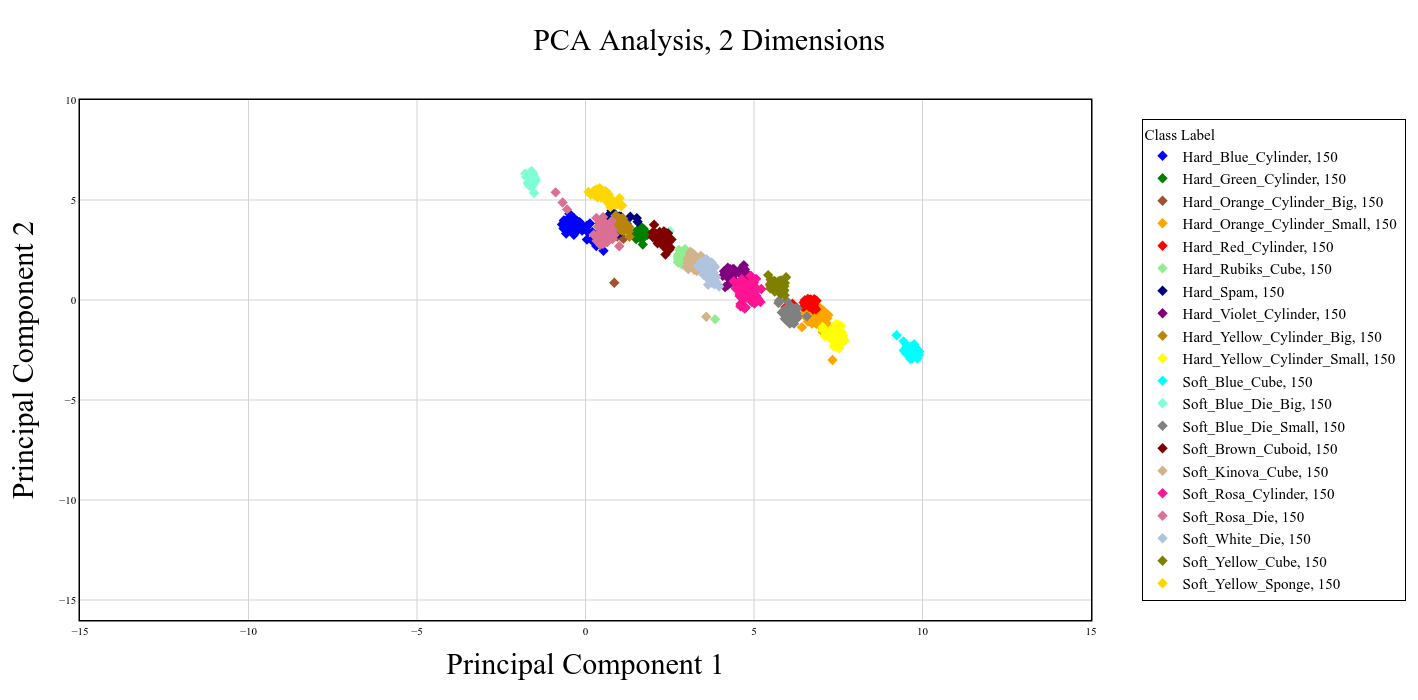

In [24]:
plot_df = pd.DataFrame({
    "PC1": PCA_1,
    "PC2": PCA_2,
    "PC3": PCA_3,
    "data_labels": data_labels,
    "loads": data_loads,
    "class": data_names
})
plot_df["class"] = pd.Categorical(
    plot_df["class"],
    categories=sorted(plot_df["class"].unique()),
    ordered=True
)
plot_df = plot_df.sort_values("class")
fig = px.scatter(
    plot_df,
    x="PC1",
    y="PC2",
    color="class",
    color_discrete_map=name_to_color,
    symbol="loads",
    symbol_map = load_to_marker_plotly,
    hover_name="data_labels",
    hover_data={"PC1": ":.3f", "PC2": ":.3f", "class": True},
    title="PCA Plot — My Dataset",
    labels={
        "PC1":   "Principal Component 1",
        "PC2":   "Principal Component 2",
        "class": "Object"
    },
)
fig.update_traces(
    textposition="top center",
    textfont=dict(size=9, family="Times New Roman"),
    marker=dict(size=8),
)
fig.update_layout(
    width=900,
    height=700,
    font=dict(family="Times New Roman", color="black"),
    title=dict(
        text="PCA Analysis, 2 Dimensions",
        x=0.5,
        font=dict(family="Times New Roman", size=30, color="black")
    ),
    xaxis=dict(
        title=dict(text="Principal Component 1", font=dict(family="Times New Roman", size=30, color="black")),
        range=[-15, 15],
        tickfont=dict(family="Times New Roman", size=11, color="black"),
        zeroline=False,
        zerolinecolor="black",
        zerolinewidth=1.5,
        showgrid=True,
        gridcolor="lightgrey",
        gridwidth=1,
        showline=True,
        linecolor="black",
        linewidth=1.5,
        mirror=True,
    ),
    yaxis=dict(
        title=dict(text="Principal Component 2", font=dict(family="Times New Roman", size=30, color="black")),
        range=[-16, 10],
        tickfont=dict(family="Times New Roman", size=11, color="black"),
        zeroline=False,
        zerolinecolor="black",
        zerolinewidth=1.5,
        showgrid=True,
        gridcolor="lightgrey",
        gridwidth=1,
        showline=True,
        linecolor="black",
        linewidth=1.5,
        mirror=True,
    ),
    legend=dict(
        traceorder="normal",
        title=dict(text="Class Label", font=dict(family="Times New Roman", size=15, color="black")),
        font=dict(family="Times New Roman", size=15, color="black"),
        bordercolor="black",
        borderwidth=1,
        x=1.05,
        y=0.5,
    ),
    plot_bgcolor="white",
)
fig.show(config={
    "toImageButtonOptions": {
        "format": "svg",
        "filename": "pca_plot",
        "width": 900,
        "height": 700,
        "scale": 1
    }
})

### 3-D Plot (Only if PCA dimension >= 3)

In [ ]:
fig = px.scatter_3d(
    plot_df,
    x = "PC1",
    y = "PC2",
    z = "PC3",
    color = "class",
    color_discrete_map = name_to_color,
    symbol = "loads",
    symbol_map = load_to_marker_plotly,
    hover_name = "data_labels",
    hover_data = {"PC1": ":.3f", "PC2": ":.3f", "PC3": ":.3f", "class": True},
    title = "PCA Analysis, 3 Dimensions",
    labels = {
        "PC1":   "Principal Component 1",
        "PC2":   "Principal Component 2",
        "PC3":   "Principal Component 3",
        "class": "Object"
    },
)
fig.update_traces(
    marker=dict(size=5, opacity=0.8),
)
fig.update_layout(
    width=900,
    height=600,
    font=dict(family="Times New Roman", color="black"),
    title=dict(
        text="PCA Analysis, 3 Dimensions",
        x=0.5,
        font=dict(family="Times New Roman", size=18, color="black")
    ),
    scene=dict(
        xaxis=dict(
            title=dict(text="Principal Component 1", font=dict(family="Times New Roman", size=12)),
            tickfont=dict(family="Times New Roman"),
            backgroundcolor="white",
            gridcolor="lightgrey",
            gridwidth=1,
            showgrid=True,
            zeroline=True,
            zerolinecolor="black",
            showline=True,
            linecolor="black",
        ),
        yaxis=dict(
            title=dict(text="Principal Component 2", font=dict(family="Times New Roman", size=12)),
            tickfont=dict(family="Times New Roman"),
            backgroundcolor="white",
            gridcolor="lightgrey",
            gridwidth=1,
            showgrid=True,
            zeroline=True,
            zerolinecolor="black",
            showline=True,
            linecolor="black",
        ),
        zaxis=dict(
            title=dict(text="Principal Component 3", font=dict(family="Times New Roman", size=12)),
            tickfont=dict(family="Times New Roman"),
            backgroundcolor="white",
            gridcolor="lightgrey",
            gridwidth=1,
            showgrid=True,
            zeroline=True,
            zerolinecolor="black",
            showline=True,
            linecolor="black",
        ),
        bgcolor="white",
    ),
    legend=dict(
        title=dict(text="Class Label", font=dict(family="Times New Roman", size=12, color="black")),
        font=dict(family="Times New Roman", size=11, color="black"),
        bordercolor="black",
        borderwidth=1,
    ),
)
fig.show(config={
    "toImageButtonOptions": {
        "format": "svg",
        "filename": "pca_plot",
        "width": 900,
        "height": 700,
        "scale": 1
    }
})

# Classifiers

In [12]:
print("Number of samples: {}, Number of features:{}, Number of unique objects: {}".format(X_analysis.shape[0], X_analysis.shape[1], Num_IDs))

Number of samples: 1532, Number of features:105, Number of unique objects: 9


## Data preparation (single split, training-only normalisation)

The cell below performs the train/validation/test split **once** and fits the
`StandardScaler` on the **training split only**. Every classifier in this
section reuses those same arrays.

Two consequences worth noting:

1. **No normalisation leakage.** Feature extraction is per-sample and uses no
   cross-sample statistics. The only step that estimates parameters from data
   is `StandardScaler`, and it now sees training data exclusively. The frozen
   mean/standard deviation are applied unchanged to validation and test.
2. **Paired model comparison.** Because the split is computed once rather than
   re-drawn inside each classifier cell, all four models are trained and
   evaluated on identical samples. This is what makes a paired significance
   test (e.g. McNemar's test on the test-set predictions) valid.

In [13]:
# ===========================================================================
# SHARED DATA PREPARATION
# ---------------------------------------------------------------------------
# This cell is the ONLY place where the dataset is split and standardised.
# All four classifiers below reuse exactly these arrays, so:
#   * every model sees identical train / validation / test samples
#     (the comparison between classifiers is therefore paired), and
#   * normalisation parameters are estimated from the TRAINING split only.
#
# Leakage note: StandardScaler.fit() is called on X_train_raw alone. The
# resulting per-feature means and standard deviations are then applied,
# unchanged, to the validation and test splits via .transform(). No statistic
# derived from validation or test data influences training in any way.
# ===========================================================================

test_size = 0.2        # 20% of all data is held out for testing
validation_size = 0.25 # 25% of the remaining 80%  ->  20% of all data
random_state = 42

np.random.seed(random_state)
torch.manual_seed(random_state)

# ---- Labels: encode once, reuse for every model ---------------------------
le = LabelEncoder()
y_all = le.fit_transform(data_class_labels)   # -> 0, 1, 2, ... n_classes-1
class_names = le.classes_
n_classes = len(class_names)

# ---- Features: RAW / unscaled at this point -------------------------------
X_all = np.asarray(X_analysis, dtype=float)

# ---- Single stratified split: train / validation / test -------------------
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_all, y_all,
    test_size=test_size,
    random_state=random_state,
    stratify=y_all,
)

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_raw, y_train,
    test_size=validation_size,
    random_state=random_state,
    stratify=y_train,
)

# ---- Normalisation: PARAMETERS FROM THE TRAINING SPLIT ONLY ---------------
scaler = StandardScaler()
scaler.fit(X_train_raw)                    # mu, sigma estimated on training data only

X_train = scaler.transform(X_train_raw)    # same frozen parameters ...
X_val   = scaler.transform(X_val_raw)      # ... applied to validation ...
X_test  = scaler.transform(X_test_raw)     # ... and to test

print("Split sizes   -> train: {}, validation: {}, test: {}".format(
    X_train.shape[0], X_val.shape[0], X_test.shape[0]))
print("Feature count -> {}".format(X_train.shape[1]))
print("Classes       -> {}".format(n_classes))
print("Sanity check  -> train mean ~0: {:.2e}, train std ~1: {:.4f}".format(
    X_train.mean(), X_train.std()))
print("               (val/test means are NOT forced to 0 - as expected: "
      "{:.3f} / {:.3f})".format(X_val.mean(), X_test.mean()))

Split sizes   -> train: 918, validation: 307, test: 307
Feature count -> 105
Classes       -> 9
Sanity check  -> train mean ~0: -7.64e-16, train std ~1: 1.0000
               (val/test means are NOT forced to 0 - as expected: 0.009 / 0.014)


## K-Nearest Neighours Classifier

In [14]:
from sklearn.neighbors import KNeighborsClassifier

In [15]:
num_neighbors = 5

# Create KNN Model
model = KNeighborsClassifier(n_neighbors=num_neighbors)

# Train model (uses the shared, training-only-scaled data)
model.fit(X_train, y_train)

# Validate  (on the held-out validation split, NOT on the training data)
y_val_pred = model.predict(X_val)
print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
validation_cm = confusion_matrix(y_val, y_val_pred)

# Evaluate
y_pred = model.predict(X_test)
print("Test Accuracy:", accuracy_score(y_test, y_pred))
#print(classification_report(y_test, y_pred))
test_cm = confusion_matrix(y_test, y_pred)

# Training accuracy, printed for reference only (not a performance measure)
print("Training Accuracy (reference only):", accuracy_score(y_train, model.predict(X_train)))

Validation Accuracy: 0.8892508143322475
Test Accuracy: 0.9055374592833876
Training Accuracy (reference only): 0.9433551198257081


Text(0.5, 1.0, 'Confusion Matrix on testing set')

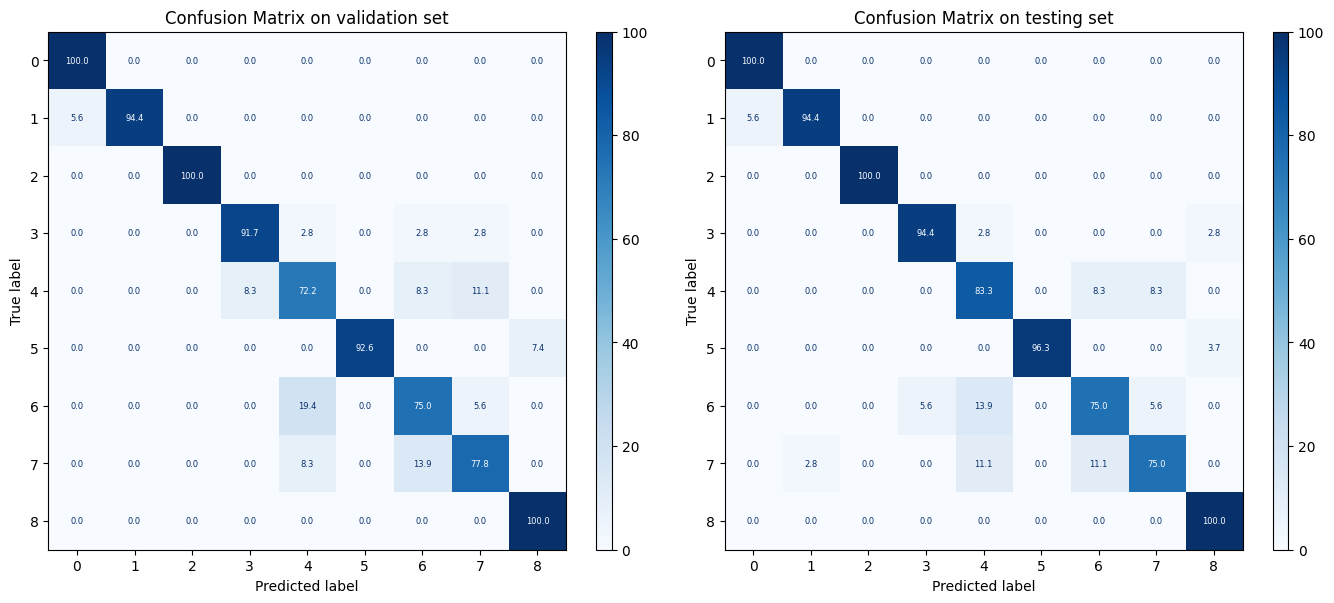

In [16]:
validation_cm = validation_cm.astype(float) / validation_cm.astype(float).sum(axis=1, keepdims=True) * 100
test_cm = test_cm.astype(float) / test_cm.astype(float).sum(axis=1, keepdims=True) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

disp = ConfusionMatrixDisplay(confusion_matrix = validation_cm)
disp.plot(ax=ax1, colorbar=False, cmap="Blues", values_format=".1f")
divider = make_axes_locatable(ax1)
cax1 = divider.append_axes("right", size="3%", pad=0.3)
plt.colorbar(ax1.images[0], cax=cax1)
for text in ax1.texts:
    text.set_fontsize(6)
ax1.set_title("Confusion Matrix on validation set")

disp = ConfusionMatrixDisplay(confusion_matrix = test_cm)
disp.plot(ax=ax2, colorbar=False, cmap="Blues", values_format=".1f")
divider = make_axes_locatable(ax2)
cax2 = divider.append_axes("right", size="3%", pad=0.3)
plt.colorbar(ax1.images[0], cax=cax2)
for text in ax2.texts:
    text.set_fontsize(6)
ax2.set_title("Confusion Matrix on testing set")

## SVM Classifier

In [17]:
from sklearn.svm import SVC

In [18]:
# Create SVM Model
model = SVC(kernel='linear', C=1.0, gamma='scale')

# Train model (uses the shared, training-only-scaled data)
model.fit(X_train, y_train)

# Validate  (on the held-out validation split, NOT on the training data)
y_val_pred = model.predict(X_val)
print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
validation_cm = confusion_matrix(y_val, y_val_pred)

# Evaluate
y_pred = model.predict(X_test)
print("Test Accuracy:", accuracy_score(y_test, y_pred))
#print(classification_report(y_test, y_pred))
test_cm = confusion_matrix(y_test, y_pred)

# Training accuracy, printed for reference only (not a performance measure)
print("Training Accuracy (reference only):", accuracy_score(y_train, model.predict(X_train)))

Validation Accuracy: 0.9674267100977199
Test Accuracy: 0.9576547231270358
Training Accuracy (reference only): 0.9945533769063181


Text(0.5, 1.0, 'Confusion Matrix on testing set')

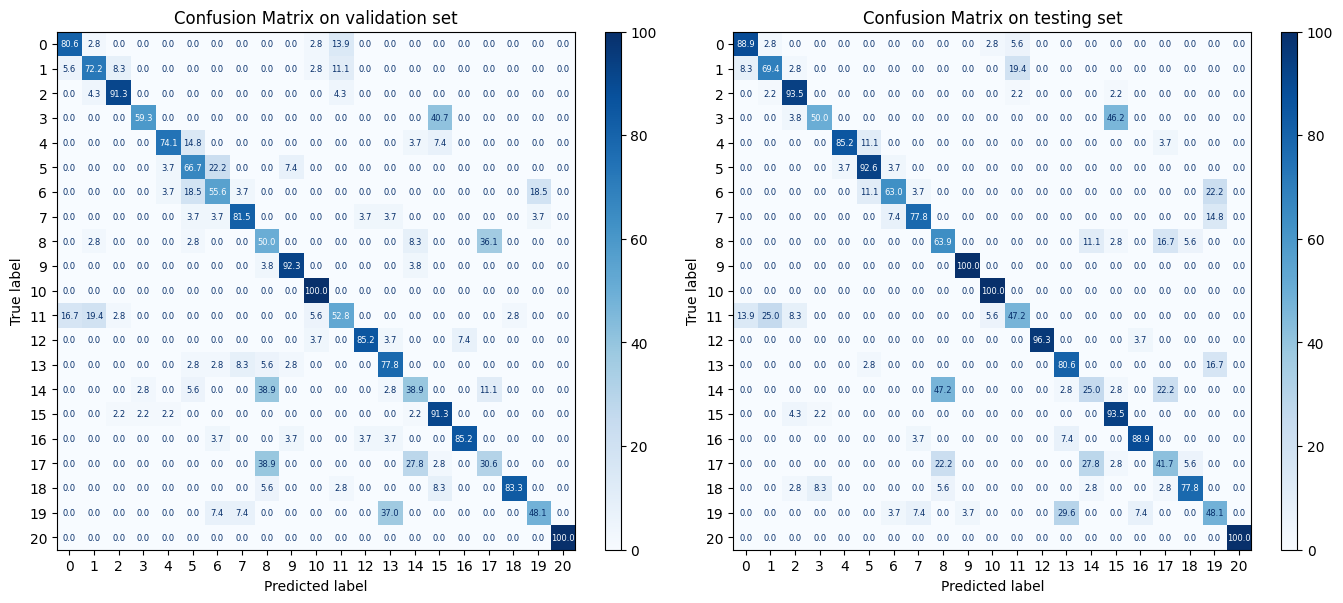

In [19]:
validation_cm = validation_cm.astype(float) / validation_cm.astype(float).sum(axis=1, keepdims=True) * 100
test_cm = test_cm.astype(float) / test_cm.astype(float).sum(axis=1, keepdims=True) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

disp = ConfusionMatrixDisplay(confusion_matrix = validation_cm)
disp.plot(ax=ax1, colorbar=False, cmap="Blues", values_format=".1f")
divider = make_axes_locatable(ax1)
cax1 = divider.append_axes("right", size="3%", pad=0.3)
plt.colorbar(ax1.images[0], cax=cax1)
for text in ax1.texts:
    text.set_fontsize(6)
ax1.set_title("Confusion Matrix on validation set")

disp = ConfusionMatrixDisplay(confusion_matrix = test_cm)
disp.plot(ax=ax2, colorbar=False, cmap="Blues", values_format=".1f")
divider = make_axes_locatable(ax2)
cax2 = divider.append_axes("right", size="3%", pad=0.3)
plt.colorbar(ax1.images[0], cax=cax2)
for text in ax2.texts:
    text.set_fontsize(6)
ax2.set_title("Confusion Matrix on testing set")

## XGBoost Classifier

In [20]:
from xgboost import XGBClassifier

In [21]:
# Create XGBoost Model
# (Tree ensembles are scale-invariant, so the standardisation does not change
#  these results - the shared arrays are used purely for consistency.)
model = XGBClassifier(
    objective='multi:softmax',
    num_class=n_classes,
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=random_state
)

# Train XGBoost on the shared encoded labels
model.fit(X_train, y_train)

# Validate  (on the held-out validation split, NOT on the training data)
y_val_pred = model.predict(X_val)
print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
validation_cm = confusion_matrix(y_val, y_val_pred)

# Evaluate
y_pred = model.predict(X_test)
print("Test Accuracy:", accuracy_score(y_test, y_pred))
#print(classification_report(y_test, y_pred))
test_cm = confusion_matrix(y_test, y_pred)

# Training accuracy, printed for reference only (not a performance measure)
print("Training Accuracy (reference only):", accuracy_score(y_train, model.predict(X_train)))

sh: 1: nvidia-smi: not found


Validation Accuracy: 0.8704512372634643
Test Accuracy: 0.8631732168850073
Training Accuracy (reference only): 1.0


Text(0.5, 1.0, 'Confusion Matrix on testing set')

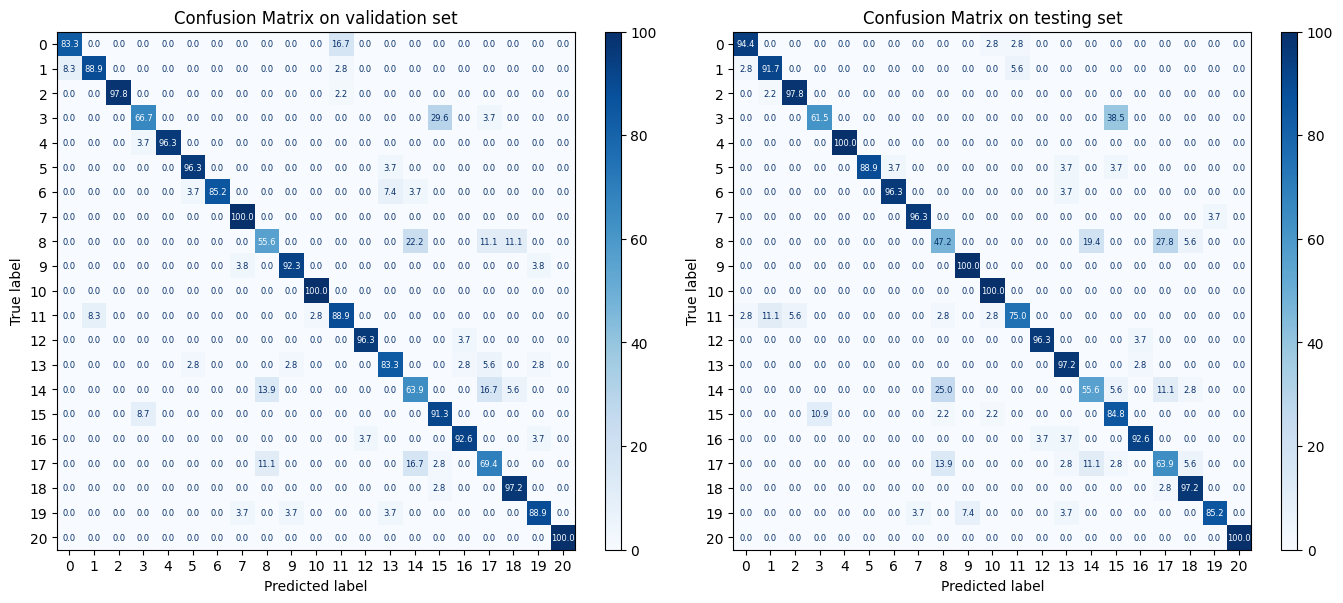

In [22]:
validation_cm = validation_cm.astype(float) / validation_cm.astype(float).sum(axis=1, keepdims=True) * 100
test_cm = test_cm.astype(float) / test_cm.astype(float).sum(axis=1, keepdims=True) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

disp = ConfusionMatrixDisplay(confusion_matrix = validation_cm)
disp.plot(ax=ax1, colorbar=False, cmap="Blues", values_format=".1f")
divider = make_axes_locatable(ax1)
cax1 = divider.append_axes("right", size="3%", pad=0.3)
plt.colorbar(ax1.images[0], cax=cax1)
for text in ax1.texts:
    text.set_fontsize(6)
ax1.set_title("Confusion Matrix on validation set")

disp = ConfusionMatrixDisplay(confusion_matrix = test_cm)
disp.plot(ax=ax2, colorbar=False, cmap="Blues", values_format=".1f")
divider = make_axes_locatable(ax2)
cax2 = divider.append_axes("right", size="3%", pad=0.3)
plt.colorbar(ax1.images[0], cax=cax2)
for text in ax2.texts:
    text.set_fontsize(6)
ax2.set_title("Confusion Matrix on testing set")

## Multi-Layer Perceptron Classifier

In [23]:
# MLP Model
input_size = X_analysis.shape[1]
output_size = Num_IDs

class MLPClassifier(nn.Module):
    def __init__(self):
        super(MLPClassifier, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, output_size)
        )

    def forward(self, x):
        return self.network(x)

In [24]:
epochs = 30

# Convert the shared splits to tensors (already scaled with training-set stats)
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_valid_tensor = torch.tensor(X_val, dtype=torch.float32)
y_valid_tensor = torch.tensor(y_val, dtype=torch.long)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

# DataLoader
train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=8, shuffle=True)
val_loader = DataLoader(TensorDataset(X_valid_tensor, y_valid_tensor), batch_size=4)
test_loader = DataLoader(TensorDataset(X_test_tensor, y_test_tensor), batch_size=4)

model = MLPClassifier()

# Loss + Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [25]:
best_accuracy = 0.0

# Training
for epoch in range(epochs):
    model.train()
    total_loss = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    # Validation accuracy check after each epoch
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:        # ← use your validation loader here
            outputs = model(X_batch)
            _, predicted = torch.max(outputs, 1)
            total += y_batch.size(0)
            correct += (predicted == y_batch).sum().item()

    val_accuracy = correct / total
    print(f"Epoch {epoch+1}, Loss: {total_loss:.4f}, Val Accuracy: {val_accuracy:.4f}")

    # Save if this is the best model so far
    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        torch.save(model.state_dict(), "./best_mlp_model.pth")
        print(f"  ✓ Best model saved (accuracy: {best_accuracy:.4f})")

# Final test evaluation
model.load_state_dict(torch.load("./best_mlp_model.pth"))
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        outputs = model(X_batch)
        _, predicted = torch.max(outputs, 1)
        total += y_batch.size(0)
        correct += (predicted == y_batch).sum().item()
print("Test Accuracy:", correct / total)

Epoch 1, Loss: 694.3786, Val Accuracy: 0.2416
  ✓ Best model saved (accuracy: 0.2416)
Epoch 2, Loss: 520.6914, Val Accuracy: 0.3755
  ✓ Best model saved (accuracy: 0.3755)
Epoch 3, Loss: 445.6103, Val Accuracy: 0.5095
  ✓ Best model saved (accuracy: 0.5095)
Epoch 4, Loss: 395.7991, Val Accuracy: 0.4934
Epoch 5, Loss: 363.3294, Val Accuracy: 0.5822
  ✓ Best model saved (accuracy: 0.5822)
Epoch 6, Loss: 326.2664, Val Accuracy: 0.5531
Epoch 7, Loss: 302.5449, Val Accuracy: 0.5968
  ✓ Best model saved (accuracy: 0.5968)
Epoch 8, Loss: 294.3944, Val Accuracy: 0.6667
  ✓ Best model saved (accuracy: 0.6667)
Epoch 9, Loss: 282.0570, Val Accuracy: 0.6667
Epoch 10, Loss: 265.7839, Val Accuracy: 0.6361
Epoch 11, Loss: 252.0948, Val Accuracy: 0.6536
Epoch 12, Loss: 247.3152, Val Accuracy: 0.7307
  ✓ Best model saved (accuracy: 0.7307)
Epoch 13, Loss: 233.7920, Val Accuracy: 0.6841
Epoch 14, Loss: 241.8005, Val Accuracy: 0.7001
Epoch 15, Loss: 224.1173, Val Accuracy: 0.7307
Epoch 16, Loss: 230.6661

Text(0.5, 1.0, 'Confusion Matrix on testing set')

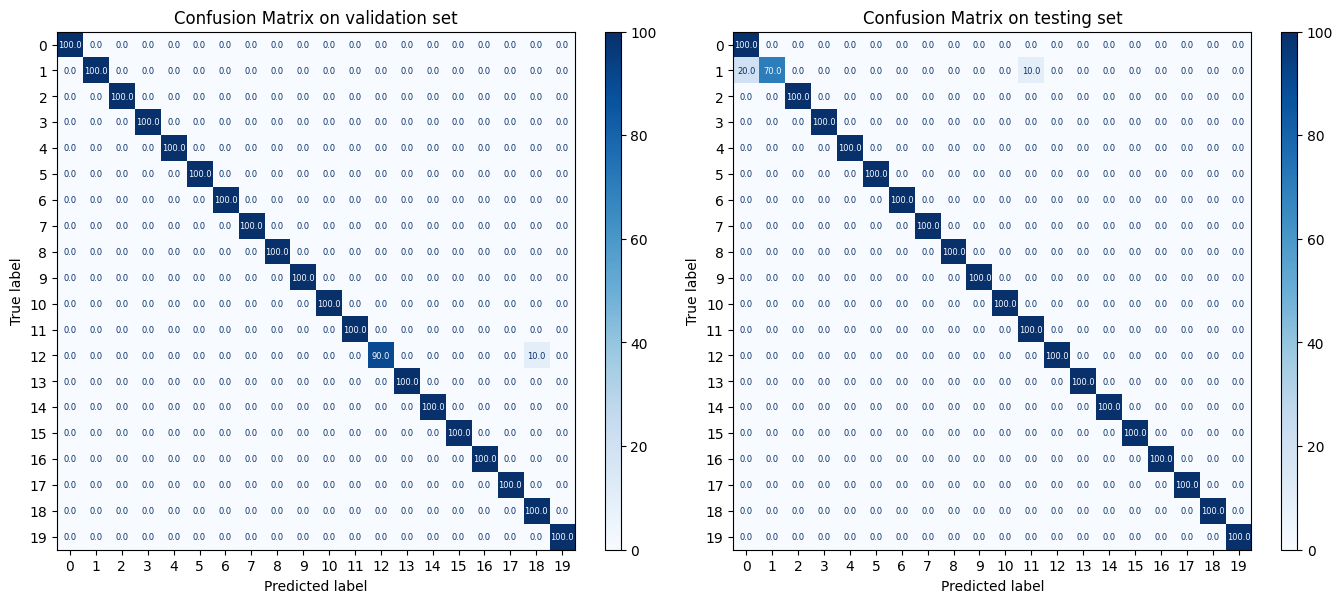

In [70]:
#Testing the network
model.eval()
with torch.no_grad():
    _, y_val_pred = torch.max(model(X_valid_tensor), 1)
    _, y_pred = torch.max(model(X_test_tensor), 1)

validation_cm = confusion_matrix(y_val, y_val_pred.numpy())
test_cm = confusion_matrix(y_test, y_pred.numpy())

validation_cm = validation_cm.astype(float) / validation_cm.astype(float).sum(axis=1, keepdims=True) * 100
test_cm = test_cm.astype(float) / test_cm.astype(float).sum(axis=1, keepdims=True) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

disp = ConfusionMatrixDisplay(confusion_matrix = validation_cm)
disp.plot(ax=ax1, colorbar=False, cmap="Blues", values_format=".1f")
divider = make_axes_locatable(ax1)
cax1 = divider.append_axes("right", size="3%", pad=0.3)
plt.colorbar(ax1.images[0], cax=cax1)
for text in ax1.texts:
    text.set_fontsize(6)
ax1.set_title("Confusion Matrix on validation set")

disp = ConfusionMatrixDisplay(confusion_matrix = test_cm)
disp.plot(ax=ax2, colorbar=False, cmap="Blues", values_format=".1f")
divider = make_axes_locatable(ax2)
cax2 = divider.append_axes("right", size="3%", pad=0.3)
plt.colorbar(ax1.images[0], cax=cax2)
for text in ax2.texts:
    text.set_fontsize(6)
ax2.set_title("Confusion Matrix on testing set")